# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Ghifary Rafie Ananda
- NIM   : 241011401318
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 18

In [ ]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    """Membagi data menjadi data training dan testing secara acak (reproducible)."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(round(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


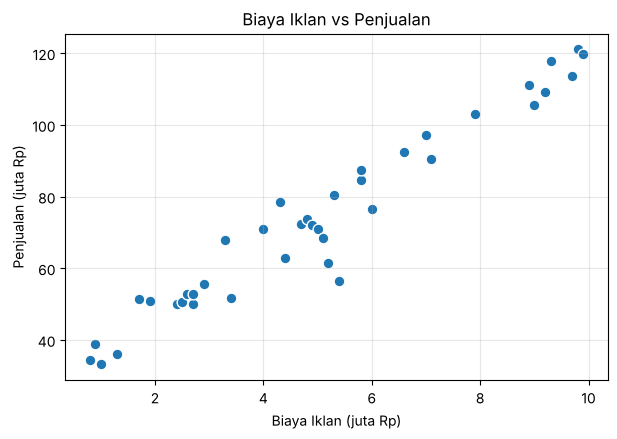

In [ ]:
df_ads = pd.read_csv("Ads_Data.csv")
display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

X = df_ads[["BiayaIklan"]].values
y = df_ads["Penjualan"].values
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X[:, 0], y, color="tab:blue", edgecolor="white", s=60)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0], 1)), X] 
        theta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y  
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b_ne = lin_reg.intercept_
m_ne = lin_reg.coef_[0]

print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * BiayaIklan")

Intercept (b)  : 29.3242
Koefisien (m)  : 9.0051
Persamaan      : y_hat = 29.3242 + 9.0051 * BiayaIklan


**Jawaban A3 (interpretasi):**

Hasil training dengan normal equation: intercept $b = 29.3242$ dan koefisien $m = 9.0051$, sehingga persamaan garis regresinya adalah

$$\hat{y} = 29.3242 + 9.0051 \cdot \text{BiayaIklan}$$

- **Arti $m = 9.0051$:** setiap kenaikan biaya iklan sebesar **1 juta Rp**, penjualan per bulan rata-rata naik sekitar **9.01 juta Rp**. Artinya, dalam data ini setiap Rp1 yang dibelanjakan untuk iklan berhubungan dengan sekitar Rp9 penjualan. Ini adalah hubungan statistik pada data yang ada, belum tentu hubungan sebab-akibat murni.
- **Arti $b = 29.3242$:** perkiraan penjualan dasar sekitar 29.32 juta Rp per bulan ketika biaya iklan mendekati nol. Perlu hati-hati karena biaya iklan 0 berada di luar rentang data (0.8 s.d. 9.9 juta), jadi $b$ lebih tepat dipandang sebagai titik potong garis daripada prediksi yang pasti.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    "Training": [mae(y_train, y_pred_train), mse(y_train, y_pred_train),
                 rmse(y_train, y_pred_train), r2_score(y_train, y_pred_train)],
    "Testing":  [mae(y_test, y_pred_test), mse(y_test, y_pred_test),
                 rmse(y_test, y_pred_test), r2_score(y_test, y_pred_test)],
}, index=["MAE", "MSE", "RMSE", "R2"])
display(hasil_eval.round(4))

print(f"Rata-rata Penjualan (data training): {y_train.mean():.2f}")
print(f"Rata-rata Penjualan (data testing) : {y_test.mean():.2f}")

,Training,Testing
MAE,4.0424,6.3949
MSE,31.9135,54.5504
RMSE,5.6492,7.3858
R2,0.9556,0.8152


Rata-rata Penjualan (data training): 74.72
Rata-rata Penjualan (data testing) : 72.50


**Jawaban A4 (analisis):**

| Metrik | Training | Testing |
|---|---|---|
| MAE | 4.0424 | 6.3949 |
| MSE | 31.9135 | 54.5504 |
| RMSE | 5.6492 | 7.3858 |
| $R^2$ | 0.9556 | 0.8152 |

- **RMSE:** pada data testing, RMSE = 7.39 berarti prediksi penjualan model rata-rata meleset sekitar **7.39 juta Rp** dari nilai sebenarnya (dalam satuan yang sama dengan `Penjualan`). Dibandingkan dengan rata-rata penjualan data testing (72.50 juta), kesalahan itu sekitar 10%. Pada data training RMSE lebih kecil, yaitu 5.65 juta (sekitar 7.6% dari rata-rata penjualan training 74.72 juta).
- **$R^2$:** pada data training $R^2 = 0.9556$, artinya sekitar 95.6% variasi penjualan dapat dijelaskan oleh biaya iklan. Pada data testing $R^2 = 0.8152$, artinya sekitar 81.5% variasi pada data yang belum pernah dilihat model masih dapat dijelaskan.
- **Apakah model sudah baik?** Ya, model ini sudah **cukup baik** karena $R^2$ testing masih di atas 0.8 dan error relatifnya sekitar 10%. Hubungan biaya iklan dan penjualan memang kuat dan mendekati linear (korelasi pada seluruh data sekitar 0.97).
- **Catatan:** nilai testing lebih buruk daripada training (selisih $R^2$ sekitar 0.14). Penyebab utamanya kemungkinan jumlah data testing yang sangat sedikit (hanya 8 data) sehingga satu data yang menyimpang cukup mempengaruhi hasil, misalnya biaya iklan 5.2 juta dengan penjualan 61.5 juta yang meleset sekitar 14.65 juta dari garis. Karena model hanya punya 2 parameter, selisih ini lebih tepat dibaca sebagai variasi akibat data testing yang kecil, bukan overfitting yang parah.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- Training learning_rate = 0.001 ---
--- Training learning_rate = 0.02 ---


--- Training learning_rate = 0.1 ---


/tmp/ipykernel_651/3495716843.py:19: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(error ** 2))           # MSE
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_651/3495716843.py:22: RuntimeWarning: overflow encountered in matmul
  self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)
/tmp/ipykernel_651/3495716843.py:22: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)


,Metode,Learning rate,Intercept,Koefisien,Loss akhir (MSE train)
0,Normal Equation,-,29.324221,9.005114,31.913529
1,Gradient Descent,0.001,26.950691,9.360907,33.322760
2,Gradient Descent,0.02,29.324221,9.005114,31.913529
3,Gradient Descent,0.1,NaN,NaN,NaN


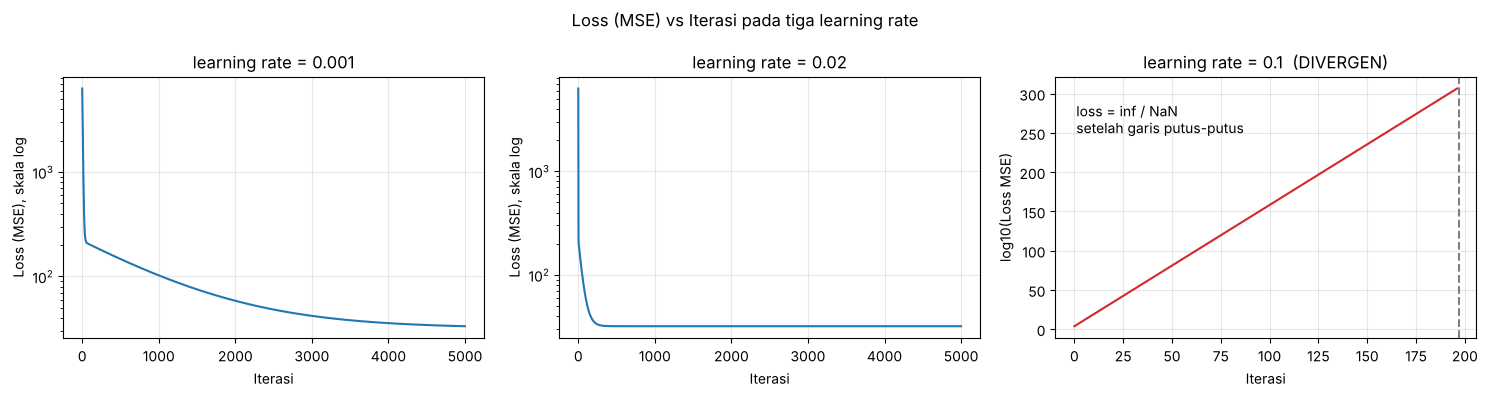

lr=0.001: loss awal=6300.62, loss akhir=33.32, loss tidak terhingga/nan mulai iterasi: tidak ada
lr=0.02: loss awal=6300.62, loss akhir=31.91, loss tidak terhingga/nan mulai iterasi: tidak ada
lr=0.1: loss awal=6300.62, loss akhir=nan, loss tidak terhingga/nan mulai iterasi: 197

Eigenvalue terbesar Hessian = 69.25 -> batas learning rate stabil = 2/lambda_max = 0.0289


In [ ]:
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        n = X.shape[0]
        self.coef_ = np.zeros(X.shape[1])
        self.intercept_ = 0.0
        self.loss_history = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history.append(np.mean(error ** 2))
            self.intercept_ -= self.learning_rate * (2 / n) * np.sum(error)
            self.coef_ -= self.learning_rate * (2 / n) * (X.T @ error)
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}
rows = [{"Metode": "Normal Equation", "Learning rate": "-",
         "Intercept": b_ne, "Koefisien": m_ne, "Loss akhir (MSE train)": mse(y_train, y_pred_train)}]

for lr in learning_rates:
    print(f"--- Training learning_rate = {lr} ---")
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    models_gd[lr] = gd
    rows.append({"Metode": "Gradient Descent", "Learning rate": lr,
                 "Intercept": gd.intercept_, "Koefisien": gd.coef_[0],
                 "Loss akhir (MSE train)": gd.loss_history[-1]})

display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(models_gd[lr].loss_history, dtype=float)
    loss[~np.isfinite(loss)] = np.nan
    if np.isnan(loss).any():
        ax.plot(np.log10(loss), color="tab:red")
        ax.set_ylabel("log10(Loss MSE)")
        ax.set_title(f"learning rate = {lr}  (DIVERGEN)")
        ax.axvline(np.where(np.isnan(loss))[0][0], color="gray", linestyle="--")
        ax.text(0.05, 0.9, "loss = inf / NaN\nsetelah garis putus-putus", transform=ax.transAxes, va="top")
    else:
        ax.plot(loss)
        ax.set_yscale("log")
        ax.set_ylabel("Loss (MSE), skala log")
        ax.set_title(f"learning rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.grid(alpha=0.3)
plt.suptitle("Loss (MSE) vs Iterasi pada tiga learning rate")
plt.tight_layout()
plt.show()

for lr in learning_rates:
    loss = np.array(models_gd[lr].loss_history, dtype=float)
    bad = np.where(~np.isfinite(loss))[0]
    awal = f"{loss[0]:.2f}"
    print(f"lr={lr}: loss awal={awal}, loss akhir={loss[-1]:.4g}, "
          f"loss tidak terhingga/nan mulai iterasi: {bad[0] if len(bad) else 'tidak ada'}")

X_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]
lambda_max = np.linalg.eigvalsh((2 / X_b.shape[0]) * X_b.T @ X_b).max()
print(f"\nEigenvalue terbesar Hessian = {lambda_max:.2f} -> batas learning rate stabil = 2/lambda_max = {2 / lambda_max:.4f}")

**Jawaban A5 (analisis):**

Hasil perbandingan dengan normal equation ($b = 29.3242$, $m = 9.0051$, MSE training = 31.9135):

| Learning rate | Intercept | Koefisien | Loss akhir (MSE) | Kondisi |
|---|---|---|---|---|
| 0.001 | 26.9507 | 9.3609 | 33.3228 | Terlalu lambat, belum konvergen |
| 0.02 | 29.3242 | 9.0051 | 31.9135 | Pas, konvergen |
| 0.1 | NaN | NaN | NaN | Divergen |

- **0.001 (terlalu lambat):** loss turun stabil tetapi sangat pelan. Loss masih sekitar 102 pada iterasi ke-1000 dan sekitar 58 pada iterasi ke-2000, dan baru 33.32 setelah 5000 iterasi, masih di atas 31.91 milik normal equation. Akibatnya intercept (26.95) dan koefisien (9.36) masih berbeda dari solusi optimal (29.32 dan 9.01). Langkah update terlalu kecil sehingga 5000 iterasi belum cukup, perlu iterasi lebih banyak.
- **0.02 (pas):** loss turun cepat dan sudah mencapai sekitar 31.92 pada iterasi ke-500, lalu datar di 31.9135. Intercept dan koefisien akhirnya identik dengan normal equation sampai 6 angka di belakang koma. Jadi gradient descent dengan learning rate yang tepat memberi solusi yang sama dengan normal equation.
- **0.1 (divergen):** loss justru membesar, dari 6300.6 pada iterasi pertama menjadi sekitar 213 ribu, lalu 7.5 juta, dan seterusnya naik sekitar 34 sampai 35 kali lipat per iterasi (grafik memakai log10(loss) dan terlihat naik lurus). Sekitar iterasi ke-197 nilainya melampaui batas bilangan float64 (menjadi `inf`) lalu `NaN`, sehingga intercept dan koefisien juga `NaN`.
- **Mengapa bisa terjadi:** setiap iterasi memindahkan parameter sejauh learning rate dikali gradien. Jika langkahnya terlalu besar, parameter melompati titik minimum ke sisi seberang yang lebih curam, sehingga error makin besar di setiap iterasi. Secara teori, GD untuk MSE hanya stabil jika $\text{lr} < 2/\lambda_{max}$, dengan $\lambda_{max}$ adalah eigenvalue terbesar Hessian MSE. Pada data ini $\lambda_{max} = 69.25$, sehingga batasnya sekitar **0.0289**. Learning rate 0.02 berada di bawah batas (stabil), sedangkan 0.1 berada di atasnya (divergen).
- **Arti `RuntimeWarning: overflow`:** angka yang dihitung sudah terlalu besar untuk ditampung tipe float64 (sekitar $1.8 \times 10^{308}$), sehingga hasilnya menjadi `inf`. Operasi berikutnya yang melibatkan `inf` (misalnya `inf - inf`) menghasilkan `NaN` dan memunculkan peringatan `invalid value`. Ini adalah tanda bahwa proses training gagal konvergen karena learning rate terlalu besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

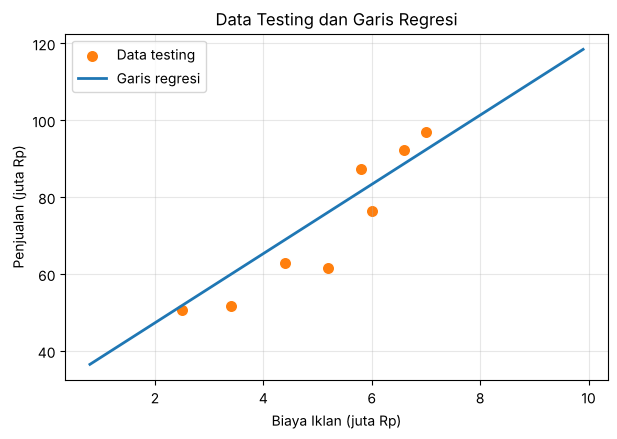

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp),Di dalam rentang data?
0,4.5,69.85,True
1,7.0,92.36,True
2,12.0,137.39,False


Rentang BiayaIklan pada dataset: 0.8 s.d. 9.9 juta Rp


In [ ]:
x_garis = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test[:, 0], y_test, color="tab:orange", edgecolor="white", s=80, label="Data testing")
plt.plot(x_garis, lin_reg.predict(x_garis), color="tab:blue", linewidth=2, label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_reg.predict(biaya_baru)
hasil_pred = pd.DataFrame({
    "BiayaIklan (juta Rp)": biaya_baru[:, 0],
    "Prediksi Penjualan (juta Rp)": pred_baru,
    "Di dalam rentang data?": (biaya_baru[:, 0] >= X.min()) & (biaya_baru[:, 0] <= X.max()),
})
display(hasil_pred.round(2))
print(f"Rentang BiayaIklan pada dataset: {X.min()} s.d. {X.max()} juta Rp")

**Jawaban A6 (analisis):**

Prediksi penjualan dari model $\hat{y} = 29.3242 + 9.0051 \cdot \text{BiayaIklan}$:

| Biaya Iklan | Prediksi Penjualan | Posisi terhadap data |
|---|---|---|
| 4.5 juta | 69.85 juta | di dalam rentang |
| 7 juta | 92.36 juta | di dalam rentang |
| 12 juta | 137.39 juta | di luar rentang (ekstrapolasi) |

Pada grafik, titik data testing tersebar di sekitar garis regresi: sebagian besar titik berada cukup dekat dengan garis, dengan penyimpangan terbesar pada biaya iklan 5.2 juta (aktual 61.5 juta, prediksi 76.15 juta).

**Kepercayaan terhadap prediksi 12 juta:** hasil 137.39 juta **kurang dapat dipercaya**. Alasannya:
1. Biaya iklan pada dataset hanya berkisar 0.8 s.d. 9.9 juta dan penjualan tertinggi yang pernah teramati adalah 121.1 juta. Model tidak pernah melihat data di atas 9.9 juta, sehingga tidak ada bukti bahwa hubungan linear tetap berlaku di sana.
2. Dalam praktik, pengaruh iklan biasanya mengalami *diminishing returns* (semakin besar biaya, tambahan penjualan per rupiah makin kecil) dan pasar bisa jenuh. Model linear mengasumsikan kenaikan 9.01 juta per 1 juta biaya selamanya, sehingga kemungkinan terlalu optimis.
3. Ketidakpastian prediksi membesar di luar rentang data, sedangkan model sudah memiliki error sekitar 7.39 juta (RMSE testing) di dalam rentang data.

Prediksi 4.5 juta dan 7 juta (interpolasi) jauh lebih layak dipercaya karena berada di dalam rentang data yang dipakai untuk melatih model.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60
Jumlah Spam (1)       : 25
Jumlah Bukan Spam (0) : 35
Shape Xe: (60, 2) | Shape ye: (60,)


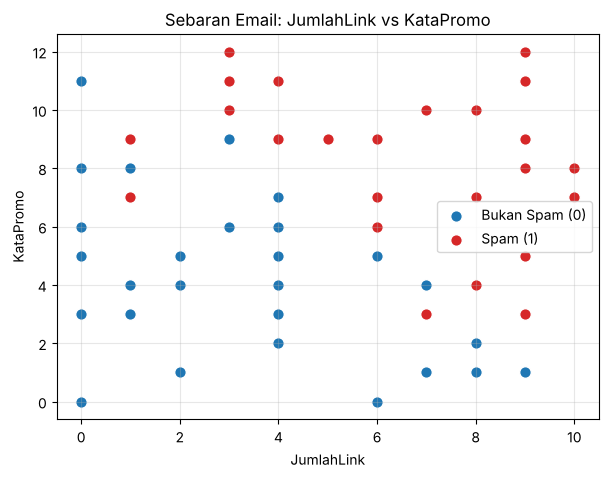

In [ ]:
df_email = pd.read_csv("Email_Data.csv")
display(df_email.head())
print("Jumlah baris data:", len(df_email))
print("Jumlah Spam (1)       :", int((df_email["Spam"] == 1).sum()))
print("Jumlah Bukan Spam (0) :", int((df_email["Spam"] == 0).sum()))

Xe = df_email[["JumlahLink", "KataPromo"]].values
ye = df_email["Spam"].values
print("Shape Xe:", Xe.shape, "| Shape ye:", ye.shape)

plt.figure(figsize=(7, 5))
plt.scatter(Xe[ye == 0, 0], Xe[ye == 0, 1], color="tab:blue", edgecolor="white", s=70, label="Bukan Spam (0)")
plt.scatter(Xe[ye == 1, 0], Xe[ye == 1, 1], color="tab:red", edgecolor="white", s=70, label="Spam (1)")
plt.title("Sebaran Email: JumlahLink vs KataPromo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train: (45, 2) | Xe_test: (15, 2)
Spam di training: 21 dari 45 | Spam di testing: 4 dari 15


Intercept (b)        : -8.5571
Koefisien m1 (Link)  : 0.7374
Koefisien m2 (Promo) : 0.7276
P(Spam) = sigmoid(-8.5571 + 0.7374 * JumlahLink + 0.7276 * KataPromo)


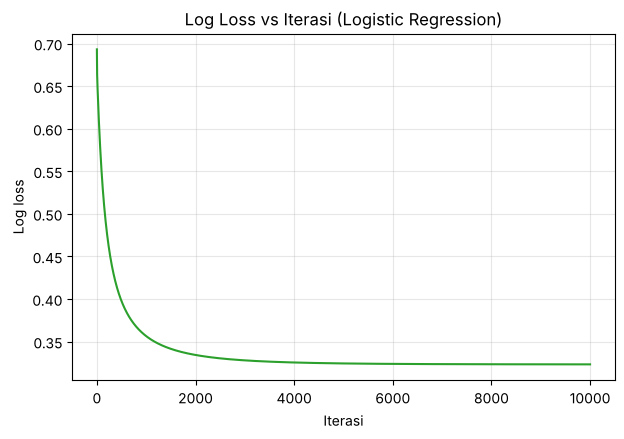

Loss iterasi ke-1     : 0.6931
Loss iterasi ke-1000  : 0.3564
Loss iterasi ke-5000  : 0.3243
Loss iterasi ke-10000 : 0.3232
Selisih loss 5000 -> 10000: 0.001080


In [ ]:
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    Xe, ye, test_size=0.25, random_state=RANDOM_STATE
)
print("Xe_train:", Xe_train.shape, "| Xe_test:", Xe_test.shape)
print("Spam di training:", int(ye_train.sum()), "dari", len(ye_train),
      "| Spam di testing:", int(ye_test.sum()), "dari", len(ye_test))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    """Logistic Regression (Gradient Descent, loss = log loss / binary cross-entropy)."""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def fit(self, X, y):
        n = X.shape[0]
        self.coef_ = np.zeros(X.shape[1])
        self.intercept_ = 0.0
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, eps, 1 - eps)
            loss = -np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
            self.loss_history.append(loss)
            error = p - y
            self.intercept_ -= self.learning_rate * np.sum(error) / n
            self.coef_ -= self.learning_rate * (X.T @ error) / n
        return self

    def predict_proba(self, X):
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)

b_lr = log_reg.intercept_
m1_lr, m2_lr = log_reg.coef_
print(f"Intercept (b)        : {b_lr:.4f}")
print(f"Koefisien m1 (Link)  : {m1_lr:.4f}")
print(f"Koefisien m2 (Promo) : {m2_lr:.4f}")
print(f"P(Spam) = sigmoid({b_lr:.4f} + {m1_lr:.4f} * JumlahLink + {m2_lr:.4f} * KataPromo)")

plt.figure(figsize=(7, 4.5))
plt.plot(log_reg.loss_history, color="tab:green")
plt.title("Log Loss vs Iterasi (Logistic Regression)")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()
print(f"Loss iterasi ke-1     : {log_reg.loss_history[0]:.4f}")
print(f"Loss iterasi ke-1000  : {log_reg.loss_history[999]:.4f}")
print(f"Loss iterasi ke-5000  : {log_reg.loss_history[4999]:.4f}")
print(f"Loss iterasi ke-10000 : {log_reg.loss_history[-1]:.4f}")
print(f"Selisih loss 5000 -> 10000: {log_reg.loss_history[4999] - log_reg.loss_history[-1]:.6f}")

**Jawaban B2 (analisis):**

Hasil training Logistic Regression (45 data training, 15 data testing): intercept $b = -8.5571$, $m_1 = 0.7374$ (JumlahLink), dan $m_2 = 0.7276$ (KataPromo), sehingga

$$P(\text{Spam}) = \sigma(-8.5571 + 0.7374 \cdot \text{JumlahLink} + 0.7276 \cdot \text{KataPromo})$$

- Kedua koefisien bernilai **positif**: semakin banyak link dan semakin banyak kata promosi, semakin besar peluang email tergolong spam. Setiap tambahan 1 link menaikkan *odds* spam sekitar $e^{0.7374} \approx 2.09$ kali, dan setiap tambahan 1 kata promosi menaikkan *odds* sekitar $e^{0.7276} \approx 2.07$ kali. Pengaruh keduanya hampir sama besar.
- **Grafik log loss:** loss turun dari 0.6931 pada iterasi pertama (sama dengan $\ln 2$, karena bobot awal nol sehingga P = 0.5), menjadi 0.3564 pada iterasi ke-1000, 0.3243 pada iterasi ke-5000, dan 0.3232 pada iterasi ke-10000.
- **Apakah sudah turun dan stabil?** Ya. Loss turun tajam di awal lalu melandai. Selisih loss antara iterasi ke-5000 dan ke-10000 hanya sekitar 0.001, sehingga model sudah hampir konvergen (kurva sudah hampir datar, walaupun masih turun sangat sedikit).

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Baris = kelas aktual, kolom = kelas prediksi -> [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred_test = log_reg.predict(Xe_test)
cm = confusion_matrix(ye_test, ye_pred_test)

print("Evaluasi pada DATA TESTING (threshold 0.5)")
print(f"Accuracy : {accuracy_score(ye_test, ye_pred_test):.4f}")
print(f"Precision: {precision_score(ye_test, ye_pred_test):.4f}")
print(f"Recall   : {recall_score(ye_test, ye_pred_test):.4f}")
print(f"F1-score : {f1_score(ye_test, ye_pred_test):.4f}")
display(pd.DataFrame(cm,
                     index=["Aktual: Bukan Spam", "Aktual: Spam"],
                     columns=["Prediksi: Bukan Spam", "Prediksi: Spam"]))
print(f"TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")

Evaluasi pada DATA TESTING (threshold 0.5)
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000


,Prediksi: Bukan Spam,Prediksi: Spam
Aktual: Bukan Spam,11,0
Aktual: Spam,0,4


TN=11, FP=0, FN=0, TP=4


**Jawaban B3 (analisis):**

Evaluasi pada data testing (15 email, threshold 0.5): accuracy = 1.0000, precision = 1.0000, recall = 1.0000, dan F1 = 1.0000. Confusion matrix: **TN = 11, FP = 0, FN = 0, TP = 4**, artinya seluruh 11 email bukan spam dan seluruh 4 email spam di data testing diklasifikasikan dengan benar.

Catatan: data testing hanya 15 email dengan 4 spam, sehingga skor sempurna ini belum bisa dianggap jaminan model selalu benar. Akurasi pada data training "hanya" 0.8667 (6 dari 45 salah), jadi nilai 100% pada testing sebagian dipengaruhi oleh pembagian data yang kecil.

- **False Positive (FP):** email yang sebenarnya **bukan spam** tetapi diprediksi **spam**, sehingga masuk ke folder spam.
- **False Negative (FN):** email yang sebenarnya **spam** tetapi diprediksi **bukan spam**, sehingga lolos masuk ke inbox.
- **Kesalahan yang lebih merugikan: FP.** Email penting (misalnya kode OTP, tagihan, undangan wawancara, atau informasi kuliah) yang salah masuk ke folder spam bisa terlewat dan menimbulkan kerugian nyata bagi pengguna. Sebaliknya, FN hanya membuat satu email spam muncul di inbox, yang menjengkelkan tetapi mudah dihapus. Karena itu pada filter spam, precision (menghindari FP) umumnya lebih diutamakan daripada recall.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.5571 + 0.7374 * JumlahLink) / 0.7276
                 = 11.7615 + (-1.0135) * JumlahLink


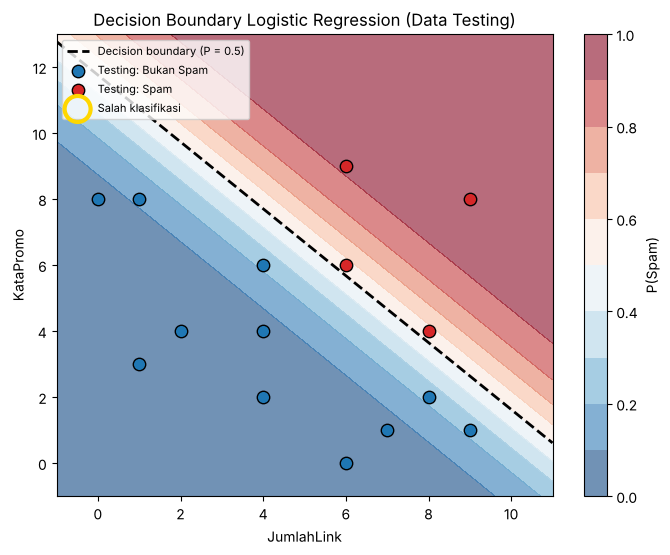

Jumlah data testing salah klasifikasi: 0 dari 15


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)


Akurasi data training = 0.8667 (6 dari 45 data training salah klasifikasi)


In [ ]:
print(f"Decision boundary: KataPromo = -({b_lr:.4f} + {m1_lr:.4f} * JumlahLink) / {m2_lr:.4f}")
print(f"                 = {-b_lr / m2_lr:.4f} + ({-m1_lr / m2_lr:.4f}) * JumlahLink")

x1_min, x1_max = Xe[:, 0].min() - 1, Xe[:, 0].max() + 1
x2_min, x2_max = Xe[:, 1].min() - 1, Xe[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
prob_grid = log_reg.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

salah = ye_pred_test != ye_test

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b_lr + m1_lr * x1_line) / m2_lr
plt.plot(x1_line, x2_line, "k--", linewidth=2, label="Decision boundary (P = 0.5)")
plt.scatter(Xe_test[(ye_test == 0), 0], Xe_test[(ye_test == 0), 1], color="tab:blue",
            edgecolor="black", s=80, label="Testing: Bukan Spam")
plt.scatter(Xe_test[(ye_test == 1), 0], Xe_test[(ye_test == 1), 1], color="tab:red",
            edgecolor="black", s=80, label="Testing: Spam")

plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], facecolors="none", edgecolors="gold",
            s=350, linewidths=3, label="Salah klasifikasi")
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary Logistic Regression (Data Testing)")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend(loc="upper left", fontsize=8)
plt.show()

df_salah = pd.DataFrame({
    "JumlahLink": Xe_test[salah, 0],
    "KataPromo": Xe_test[salah, 1],
    "Aktual": ye_test[salah],
    "Prediksi": ye_pred_test[salah],
    "P(Spam)": log_reg.predict_proba(Xe_test[salah]).round(4),
})
print(f"Jumlah data testing salah klasifikasi: {salah.sum()} dari {len(ye_test)}")
display(df_salah)

ye_pred_train = log_reg.predict(Xe_train)
print(f"Akurasi data training = {accuracy_score(ye_train, ye_pred_train):.4f} "
      f"({int((ye_pred_train != ye_train).sum())} dari {len(ye_train)} data training salah klasifikasi)")

**Jawaban B4 (analisis):**

Decision boundary (garis saat $P = 0.5$):

$$\text{KataPromo} = -\frac{-8.5571 + 0.7374 \cdot \text{JumlahLink}}{0.7276} \approx 11.76 - 1.0135 \cdot \text{JumlahLink}$$

- Kemiringan garis sekitar $-1.01$, hampir $-1$. Karena $m_1 \approx m_2$, model pada dasarnya menandai email sebagai spam jika **JumlahLink + KataPromo lebih dari sekitar 11.7**. Area di atas/kanan garis (merah pada grafik) adalah daerah Spam, dan area di bawah/kiri garis (biru) adalah daerah Bukan Spam.
- **Data testing yang salah diklasifikasikan: tidak ada (0 dari 15).** Pada grafik tidak ada titik yang ditandai lingkaran kuning, dan tabel data salah klasifikasi kosong.
- Walaupun benar semua, ada dua email spam yang berada sangat dekat garis: (JumlahLink 6, KataPromo 6) dengan $P = 0.558$ dan (8, 4) dengan $P = 0.563$. Keduanya hanya sedikit di atas 0.5 sehingga hasilnya sensitif terhadap perubahan threshold (lihat B5).
- Pada data training, ada 6 dari 45 email yang salah diklasifikasikan (akurasi 0.8667). Ini menunjukkan bahwa satu garis lurus tidak dapat memisahkan semua email dengan sempurna, karena sebagian email normal memiliki banyak kata promosi dan sebagian spam memiliki sedikit link.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
proba_test = log_reg.predict_proba(Xe_test)

rows = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    cm_th = confusion_matrix(ye_test, pred)
    rows.append({
        "Threshold": th,
        "TN": cm_th[0, 0], "FP": cm_th[0, 1], "FN": cm_th[1, 0], "TP": cm_th[1, 1],
        "Accuracy": accuracy_score(ye_test, pred),
        "Precision": precision_score(ye_test, pred),
        "Recall": recall_score(ye_test, pred),
        "F1": f1_score(ye_test, pred),
    })
tabel_threshold = pd.DataFrame(rows)
display(tabel_threshold.round(4))

THRESHOLD_PILIHAN = 0.5
print("Threshold pilihan:", THRESHOLD_PILIHAN)

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,0.3,11,0,0,4,1.0000,1.0,1.0,1.0000
1,0.5,11,0,0,4,1.0000,1.0,1.0,1.0000
2,0.7,11,0,2,2,0.8667,1.0,0.5,0.6667


Threshold pilihan: 0.5


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 0.3 | 11 | 0 | 0 | 4 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| 0.5 | 11 | 0 | 0 | 4 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| 0.7 | 11 | 0 | 2 | 2 | 0.8667 | 1.0000 | 0.5000 | 0.6667 |

**Pengaruh threshold:**
- **Menaikkan threshold** membuat model lebih "pelit" memberi label spam. FP berkurang sehingga precision cenderung naik atau tetap, tetapi FN bertambah sehingga recall turun. Pada threshold 0.7, dua email spam yang probabilitasnya 0.558 dan 0.563 tidak lagi terdeteksi, sehingga FN = 2 dan recall turun dari 1.0 menjadi 0.5, sedangkan precision tetap 1.0 karena FP memang sudah 0.
- **Menurunkan threshold** membuat model lebih mudah memberi label spam. Recall cenderung naik, tetapi risiko FP bertambah sehingga precision bisa turun. Pada data testing ini, hasil threshold 0.3 sama dengan 0.5 karena probabilitas email bukan spam tertinggi hanya 0.233 (di bawah 0.3) dan probabilitas spam terendah 0.558 (di atas 0.5).
- Inilah *trade-off* precision dan recall: keduanya sulit dinaikkan bersamaan hanya dengan mengubah threshold.

**Threshold pilihan saya: 0.5.** Berdasarkan B3, FP lebih merugikan, sehingga threshold yang terlalu rendah berisiko menyalahkan email penting. Namun threshold yang tinggi seperti 0.7 tidak memberi keuntungan: precision sudah 1.0 pada threshold 0.5, sedangkan recall merosot menjadi 0.5. Threshold 0.3 juga tidak memberi keuntungan pada data ini dan lebih berisiko menimbulkan FP pada email baru (misalnya email dengan $P = 0.376$ pada B6 akan ikut dianggap spam). Jadi 0.5 memberi keseimbangan terbaik antara precision dan recall pada hasil saya.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11],
})
p_baru = log_reg.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = p_baru.round(4)
email_baru["Prediksi"] = np.where(p_baru >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
print("Threshold yang dipakai:", THRESHOLD_PILIHAN)
display(email_baru)

Threshold yang dipakai: 0.5


,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0017,Bukan Spam
1,E2,5,6,0.3764,Bukan Spam
2,E3,9,10,0.9953,Spam
3,E4,2,11,0.7152,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena targetnya adalah **kelas** (misalnya Spam atau Bukan Spam), bukan nilai kontinu. Model tetap disebut "regression" karena di dalamnya ada persamaan linear $z = b + m_1 x_1 + m_2 x_2$ yang dicari seperti pada regresi linear. Fungsi **sigmoid** $\sigma(z) = 1/(1+e^{-z})$ mengubah $z$ (yang bisa bernilai berapa saja) menjadi probabilitas antara 0 dan 1. Probabilitas ini kemudian dibandingkan dengan threshold (default 0.5) untuk menentukan kelasnya. Contohnya pada B6, email E3 mendapat $P(\text{Spam}) = 0.9953$ sehingga diklasifikasikan Spam.

**Jawaban C2:**
**Normal equation** menghitung parameter langsung dengan rumus $\theta = (X^TX)^{-1}X^Ty$ dalam satu langkah, tanpa learning rate maupun iterasi, tetapi harus membalik matriks sehingga mahal jika jumlah fitur atau datanya sangat besar. **Gradient descent** mencari parameter secara bertahap dengan mengikuti arah turunnya loss, dan hasilnya bergantung pada learning rate dan jumlah iterasi. Pada A5, gradient descent dengan learning rate 0.02 menghasilkan intercept 29.3242 dan koefisien 9.0051 yang sama dengan normal equation. Gradient descent sebaiknya dipakai ketika data atau fiturnya sangat banyak, ketika matriks sulit dibalik, atau ketika modelnya tidak punya solusi rumus tertutup seperti Logistic Regression.

**Jawaban C3:**
Tujuan model adalah memprediksi data baru yang belum pernah dilihat, sehingga kemampuannya harus diukur pada **data testing**. Evaluasi pada data training cenderung terlalu optimistis karena model sudah "melihat" data tersebut saat belajar. **Overfitting** adalah kondisi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise-nya, sehingga sangat baik pada data training tetapi buruk pada data baru. Pada hasil saya, $R^2$ training 0.9556 lebih tinggi daripada $R^2$ testing 0.8152, yang menunjukkan bahwa performa pada data baru bisa berbeda dari performa pada data training.

**Jawaban C4:**
Output Linear Regression adalah **bilangan kontinu**, sehingga wajar mengukur error sebagai jarak kuadrat antara nilai prediksi dan nilai sebenarnya (MSE). Output Logistic Regression adalah **probabilitas** untuk label biner 0 atau 1. Jika MSE dipakai dengan sigmoid, fungsi loss menjadi tidak cembung dan gradiennya sangat kecil ketika prediksi salah dengan sangat yakin. **Log loss** (cross-entropy) berasal dari prinsip *maximum likelihood* untuk data biner, bersifat cembung terhadap parameter, dan memberi hukuman sangat besar pada prediksi yang yakin tetapi salah (misalnya memberi $P = 0.01$ pada email yang sebenarnya spam). Contohnya, loss awal saya 0.6931 ($= \ln 2$) ketika model masih menebak P = 0.5, lalu turun menjadi 0.3232 setelah training.

**Jawaban C5:**
Penyebab utamanya adalah `random_state` yang berbeda (2 digit terakhir NIM setiap mahasiswa). Nilai ini menentukan bagaimana data diacak saat `train_test_split`, sehingga data training dan data testing setiap mahasiswa berbeda. Model yang dilatih pada data training yang berbeda menghasilkan koefisien yang berbeda, dan metrik seperti $R^2$, RMSE, akurasi, dan confusion matrix dihitung pada data testing yang berbeda pula. Pada dataset yang kecil seperti ini (8 data testing pada regresi dan 15 pada klasifikasi), perbedaan tersebut bisa terlihat cukup besar. Algoritma dan datanya sama, tetapi sampel yang dipakai untuk belajar dan menguji berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# Linear Regression
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("=== Linear Regression ===")
display(pd.DataFrame({
    "Intercept": [b_ne, sk_lin.intercept_],
    "Koefisien": [m_ne, sk_lin.coef_[0]],
    "R2 testing": [r2_score(y_test, lin_reg.predict(X_test)), r2_score(y_test, sk_lin.predict(X_test))],
    "RMSE testing": [rmse(y_test, lin_reg.predict(X_test)), rmse(y_test, sk_lin.predict(X_test))],
}, index=["Implementasi sendiri", "scikit-learn"]).round(6))

# Logistic Regression
sk_log_default = SkLogisticRegression(max_iter=10000).fit(Xe_train, ye_train)
sk_log_noreg = SkLogisticRegression(C=1e10, max_iter=10000).fit(Xe_train, ye_train)

def ringkas(nama, intercept, coef, pred_test):
    return {
        "Model": nama, "Intercept": intercept, "m1 (Link)": coef[0], "m2 (Promo)": coef[1],
        "Accuracy": accuracy_score(ye_test, pred_test),
        "Precision": precision_score(ye_test, pred_test),
        "Recall": recall_score(ye_test, pred_test),
        "F1": f1_score(ye_test, pred_test),
    }

print("=== Logistic Regression ===")
display(pd.DataFrame([
    ringkas("Implementasi sendiri (tanpa regularisasi)", b_lr, log_reg.coef_, log_reg.predict(Xe_test)),
    ringkas("sklearn default (L2, C=1.0)", sk_log_default.intercept_[0], sk_log_default.coef_[0], sk_log_default.predict(Xe_test)),
    ringkas("sklearn tanpa regularisasi (C=1e10)", sk_log_noreg.intercept_[0], sk_log_noreg.coef_[0], sk_log_noreg.predict(Xe_test)),
]).round(4))

=== Linear Regression ===


,Intercept,Koefisien,R2 testing,RMSE testing
Implementasi sendiri,29.324221,9.005114,0.81521,7.385822
scikit-learn,29.324221,9.005114,0.81521,7.385822


=== Logistic Regression ===


,Model,Intercept,m1 (Link),m2 (Promo),Accuracy,Precision,Recall,F1
0,Implementasi sendiri (tanpa regularisasi),-8.5571,0.7374,0.7276,1.0,1.0,1.0,1.0
1,"sklearn default (L2, C=1.0)",-7.9577,0.6806,0.6790,1.0,1.0,1.0,1.0
2,sklearn tanpa regularisasi (C=1e10),-8.7438,0.7537,0.7426,1.0,1.0,1.0,1.0


**Jawaban Bonus (analisis):**

**Linear Regression.** Hasil scikit-learn **identik** dengan implementasi saya: intercept 29.324221, koefisien 9.005114, $R^2$ testing 0.81521, dan RMSE testing 7.385822. Hal ini wajar karena keduanya menyelesaikan masalah *least squares* yang sama dan memiliki solusi tunggal (rumus tertutup).

**Logistic Regression.** Hasilnya **berbeda** pada koefisien:

| Model | Intercept | $m_1$ (Link) | $m_2$ (Promo) |
|---|---|---|---|
| Implementasi sendiri (GD, tanpa regularisasi) | -8.5571 | 0.7374 | 0.7276 |
| scikit-learn default (L2, $C=1.0$) | -7.9577 | 0.6806 | 0.6790 |
| scikit-learn tanpa regularisasi ($C=10^{10}$) | -8.7438 | 0.7537 | 0.7426 |

Penyebab perbedaan:
1. **Regularisasi.** `LogisticRegression` scikit-learn secara default memakai penalti **L2 dengan $C = 1.0$**, yang menarik koefisien mendekati nol (sehingga nilainya 0.68 dan 0.68, lebih kecil dari 0.74 dan 0.73 pada implementasi saya). Implementasi saya tidak memakai regularisasi.
2. **Konvergensi.** Setelah regularisasi dimatikan ($C=10^{10}$), koefisien scikit-learn (-8.7438; 0.7537; 0.7426) menjadi mirip dengan milik saya, tetapi belum sama persis. Gradient descent saya berhenti setelah 10000 iterasi dan loss-nya masih turun sedikit (sekitar 0.001 antara iterasi 5000 dan 10000), sedangkan solver `lbfgs` scikit-learn berjalan sampai konvergen sehingga koefisiennya sedikit lebih besar.

Walaupun koefisiennya berbeda, **ketiga model memberi hasil evaluasi yang sama** pada data testing (accuracy, precision, recall, dan F1 semuanya 1.0), karena perbedaan koefisiennya kecil dan tidak mengubah kelas prediksi pada 15 data testing.